<a href="https://colab.research.google.com/github/Rageel-28/244107020136-Machine-Learning/blob/main/JS08/JS08_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS08 - Hierarchical Clustering
## Lab 1 - Klasterisasi Hierarkis dengan Dataset Mall Customers

**Tujuan**
1. Memahami konsep klasterisasi hierarkis (*agglomerative*, *bottom-up*).
2. Membuat dendrogram dan menentukan jumlah *cluster* dari dendrogram.
3. Membuat dan mengevaluasi model `AgglomerativeClustering`.

Kasus: mengelompokkan pelanggan *mall* berdasarkan **Annual Income** dan **Spending Score**.

## Langkah 0 - Download Dataset

Unduh `Mall_Customers.csv` dari modul praktikum, lalu letakkan satu folder dengan notebook ini (atau upload ke Google Colab). Dataset berisi 200 baris dengan kolom `CustomerID`, `Genre`, `Age`, `Annual Income (k$)`, dan `Spending Score (1-100)`.

In [1]:
import os

if not os.path.exists('Mall_Customers.csv'):
    try:
        from google.colab import files
        print('Silakan upload file Mall_Customers.csv')
        files.upload()
    except ImportError:
        pass

if not os.path.exists('Mall_Customers.csv'):
    raise FileNotFoundError('Mall_Customers.csv tidak ditemukan. Letakkan file di folder yang sama dengan notebook ini.')

print('Mall_Customers.csv ditemukan.')

Silakan upload file Mall_Customers.csv


Saving Mall_Customers.csv to Mall_Customers.csv
Mall_Customers.csv ditemukan.


## Langkah 1 - Import Library

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Langkah 2 - Load dan Inspeksi Data

In [3]:
dataset = pd.read_csv('Mall_Customers.csv')
dataset.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


## Langkah 3 - Seleksi Fitur

Hanya dua fitur yang dipakai: kolom ke-3 (`Annual Income (k$)`) dan kolom ke-4 (`Spending Score (1-100)`). Data diambil sebagai array NumPy.

In [5]:
X = dataset.iloc[:, [3, 4]].values
print(dataset.columns[[3, 4]].tolist())
print(X[:5])

['Annual Income (k$)', 'Spending Score (1-100)']
[[15 39]
 [15 81]
 [16  6]
 [16 77]
 [17 40]]


## Langkah 4 - Membuat Dendrogram

Dendrogram dibuat dengan `scipy.cluster.hierarchy` memakai *linkage* **Ward** (meminimalkan kenaikan varians dalam *cluster* saat penggabungan). Tinggi garis penggabungan menunjukkan ketidakmiripan (jarak) antar *cluster*: makin pendek makin mirip. Jumlah *cluster* ditentukan dengan "memotong" dendrogram pada ketinggian tertentu.

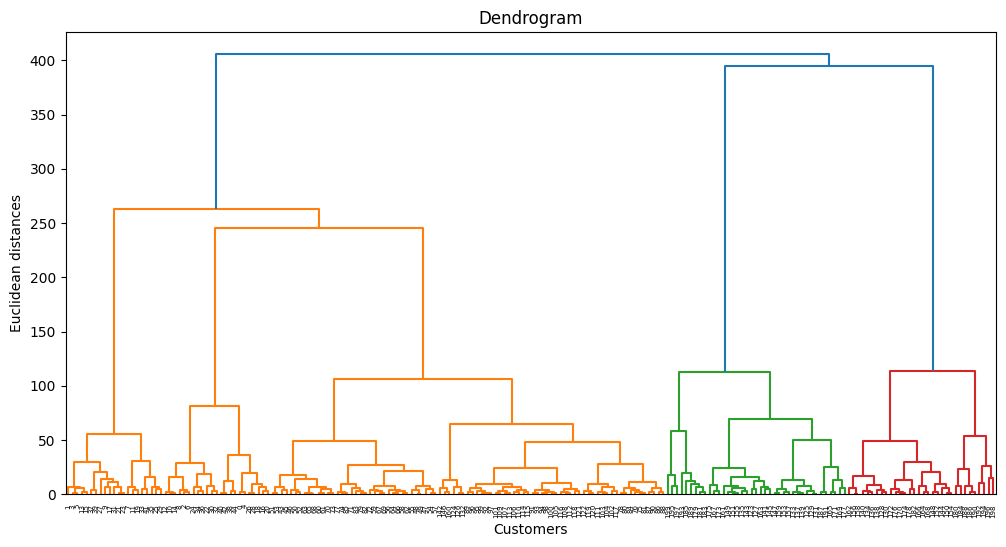

In [6]:
import scipy.cluster.hierarchy as sch

plt.figure(figsize=(12, 6))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.show()

Pada dendrogram, pemotongan pada ketinggian tinggi menghasilkan sedikit *cluster* (modul menyebut **3 *cluster* utama**), sedangkan pemotongan lebih rendah menghasilkan lebih banyak *cluster* (modul memakai **5 *cluster***). Kita akan memakai 5 *cluster*. Sel berikut menghitung ketinggian potong yang menghasilkan tepat 5 *cluster* dari data, lalu menggambarnya sebagai garis merah.

Potong pada jarak  328.71 -> 3 cluster
Potong pada jarak  179.77 -> 5 cluster


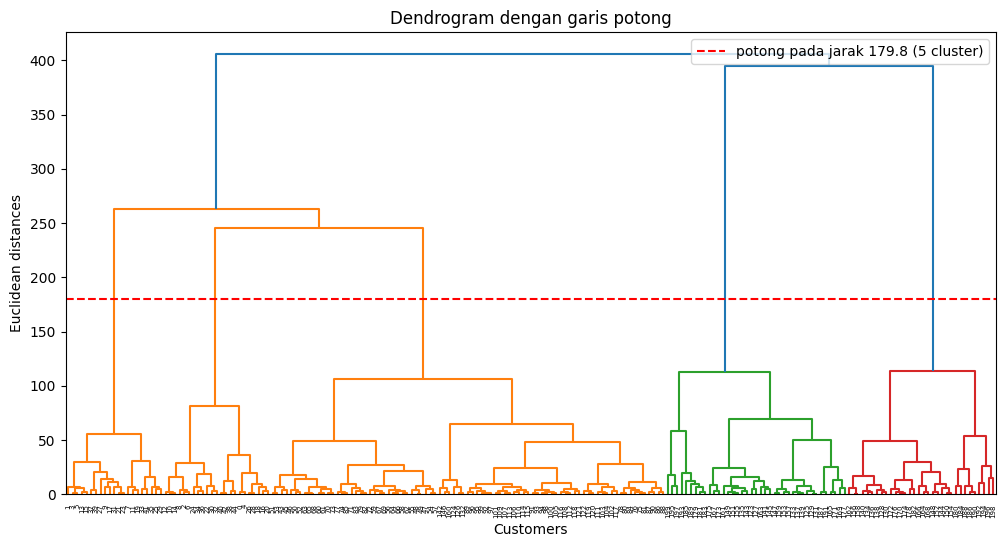

In [7]:
Z = sch.linkage(X, method='ward')

# Ketinggian potong untuk n cluster = titik tengah antara penggabungan ke-(n-1) dan ke-n terbesar
def tinggi_potong(Z, n):
    return (Z[-(n - 1), 2] + Z[-n, 2]) / 2

for n in (3, 5):
    h = tinggi_potong(Z, n)
    cek = len(set(sch.fcluster(Z, t=h, criterion='distance')))
    print(f'Potong pada jarak {h:7.2f} -> {cek} cluster')

h5 = tinggi_potong(Z, 5)
plt.figure(figsize=(12, 6))
sch.dendrogram(Z)
plt.axhline(y=h5, color='r', linestyle='--', label=f'potong pada jarak {h5:.1f} (5 cluster)')
plt.title('Dendrogram dengan garis potong')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.legend()
plt.show()

## Langkah 5 - Membuat Model Agglomerative Clustering

Gunakan `AgglomerativeClustering` dengan 5 *cluster*, jarak Euclidean, dan *linkage* Ward.

In [8]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)
print(y_hc[:20])
print(pd.Series(y_hc).value_counts().sort_index())

[4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3]
0    32
1    85
2    39
3    21
4    23
Name: count, dtype: int64


## Langkah 6 - Visualisasi Hasil Klasterisasi

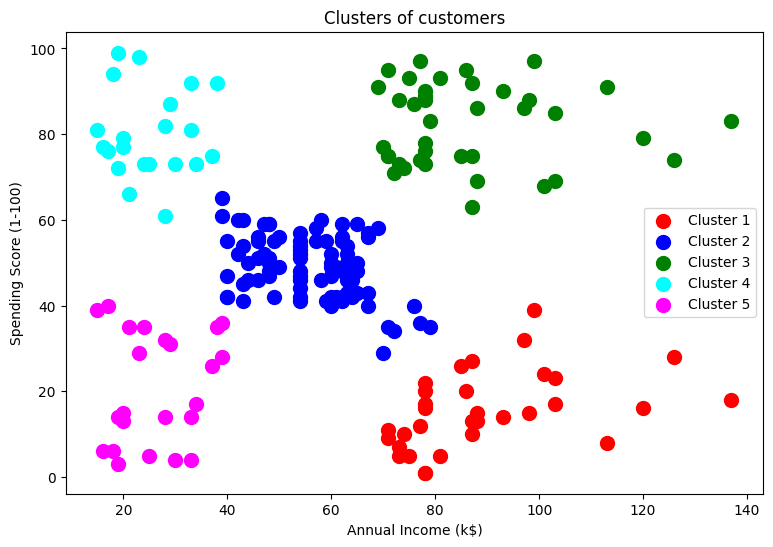

In [9]:
warna = ['red', 'blue', 'green', 'cyan', 'magenta']
plt.figure(figsize=(9, 6))
for i in range(5):
    plt.scatter(X[y_hc == i, 0], X[y_hc == i, 1], s=100, c=warna[i], label=f'Cluster {i + 1}')
plt.title('Clusters of customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

## Langkah 7 - Evaluasi dengan Silhouette Coefficient

Nilai *silhouette* berkisar −1 hingga +1; makin dekat +1 makin baik.

In [10]:
from sklearn.metrics import silhouette_score

print(f'Silhouette score (k=5): {silhouette_score(X, y_hc):.4f}')

Silhouette score (k=5): 0.5530


Nilai sekitar **0.55** dapat dikategorikan cukup baik (nilai pada modul ≈ 0.55).

## Latihan - Eksperimen Jumlah *Cluster*

Coba beberapa jumlah *cluster* dan lihat jumlah mana yang terbaik berdasarkan *silhouette score*.

 n_clusters  silhouette
          2    0.367064
          3    0.461834
          4    0.491660
          5    0.552995
          6    0.538021
          7    0.519905
          8    0.432629
          9    0.438925
         10    0.434266


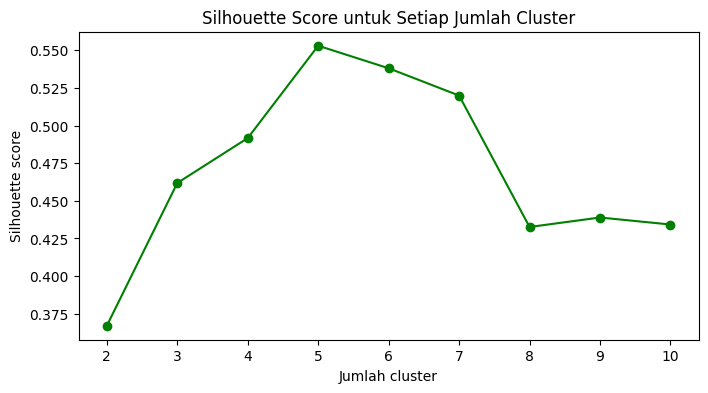


Silhouette tertinggi: k = 5 (score 0.5530)


In [11]:
hasil = []
for k in range(2, 11):
    lbl = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward').fit_predict(X)
    hasil.append((k, silhouette_score(X, lbl)))

tabel = pd.DataFrame(hasil, columns=['n_clusters', 'silhouette'])
print(tabel.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot(tabel['n_clusters'], tabel['silhouette'], 'go-')
plt.xlabel('Jumlah cluster')
plt.ylabel('Silhouette score')
plt.title('Silhouette Score untuk Setiap Jumlah Cluster')
plt.show()

terbaik = tabel.loc[tabel['silhouette'].idxmax()]
print(f"\nSilhouette tertinggi: k = {int(terbaik['n_clusters'])} (score {terbaik['silhouette']:.4f})")

In [12]:
# Bandingkan 4 jenis linkage pada k = 5
for link in ['ward', 'complete', 'average', 'single']:
    lbl = AgglomerativeClustering(n_clusters=5, linkage=link).fit_predict(X)
    print(f'linkage = {link:<8} | silhouette = {silhouette_score(X, lbl):.4f}')

linkage = ward     | silhouette = 0.5530
linkage = complete | silhouette = 0.5530
linkage = average  | silhouette = 0.4792
linkage = single   | silhouette = 0.2695


### Analisis

- Dendrogram memperlihatkan hierarki penggabungan; memotongnya pada ketinggian berbeda menghasilkan jumlah *cluster* berbeda tanpa melatih ulang.
- Jumlah *cluster* terbaik tidak harus yang diambil dari dendrogram saja: bandingkan dengan *silhouette score* pada tabel latihan di atas. Bila nilai tertinggi jatuh pada $k$ yang sama dengan hasil dendrogram, pilihan tersebut semakin kuat.
- Perbandingan *linkage* menunjukkan bahwa *single linkage* rentan membentuk rantai (satu *cluster* besar) sementara Ward cenderung menghasilkan *cluster* yang seimbang.